In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MultiLabelBinarizer
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from collections import Counter
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline, Pipeline
import seaborn as sns

In [2]:
df = pd.read_csv("../../Datasets/Processed/Dataset Dupilumab Baseline.xlsx - Anagrafica.csv")
df.shape

(112, 47)

In [3]:
df.head()

,Sesso,Età,Peso (kg),Altezza (cm),"Biologico precedente (0 no, 1 sì)",Categoria Professione,Comorbidità,Num Comorbidità,Familiarità Atopia,"Fumo Baseline (0=no, 1=ex, 2=si)",...,Ostruzione nasale,Rinorrea anteriore,Rinorrea posteriore,Dolore facciale,Starnuti,QoL,Cellule caliciformi mucipare,Citologico_Neutrofili,Citologico_Eosinofili,TARGET
0,F,61.0,66.0,167.0,0.0,Ufficio,asma,1,0.0,2,...,10.0,10.0,10.0,10.0,8.0,1.0,NaN,NaN,NaN,1
1,M,47.0,78.0,180.0,0.0,Ufficio,NaN,0,0.0,1,...,10.0,8.0,10.0,8.0,8.0,2.0,1.0,2.0,1.0,0
2,F,70.0,81.0,175.0,0.0,Disoccupati,"ipertensione, ipercolesterolemia, asma",3,1.0,1,...,8.0,6.0,8.0,0.0,8.0,3.0,1.0,1.0,2.0,1
3,F,36.0,56.0,159.0,1.0,Industria,asma,1,0.0,0,...,10.0,10.0,8.0,8.0,10.0,2.0,0.0,2.0,3.0,1
4,M,75.0,75.0,176.0,NaN,Disoccupati,"rinite, congiuntivite, k polmone, diabete 2, asma",5,0.0,1,...,8.0,4.0,8.0,4.0,8.0,5.0,NaN,NaN,NaN,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 112 entries, 0 to 111
Data columns (total 47 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   Sesso                                            112 non-null    str    
 1   Età                                              110 non-null    float64
 2   Peso (kg)                                        102 non-null    float64
 3   Altezza (cm)                                     102 non-null    float64
 4   Biologico precedente (0 no, 1 sì)                50 non-null     float64
 5   Categoria Professione                            87 non-null     str    
 6   Comorbidità                                      71 non-null     str    
 7   Num Comorbidità                                  112 non-null    int64  
 8   Familiarità Atopia                               80 non-null     float64
 9   Fumo Baseline (0=no, 1=ex, 2=si)           

In [5]:
df.columns

Index(['Sesso', 'Età', 'Peso (kg)', 'Altezza (cm)',
       'Biologico precedente (0 no, 1 sì)', 'Categoria Professione',
       'Comorbidità', 'Num Comorbidità', 'Familiarità Atopia',
       'Fumo Baseline (0=no, 1=ex, 2=si)', 'Anni di astinenza',
       'Siga al giorno', 'Fumo Score', 'OCS nell'ultimo anno',
       'Numero di brevi cicli/anno di OCS',
       'Dosaggio cumulativo annuale in mg di prednisone',
       'Numero di pregressi interventi ESS', 'N. allergeni positivi',
       'Quali allergeni positivi', 'Categorie Allergeni',
       'Intolleranza ai FANS', 'Giorni al mese di utilizzo spray', 'ACT',
       'NPS', 'Neutrofili', 'Linfociti', 'Monociti', 'Eosinofili', 'Basofili',
       'IgE totali', 'Physical Symptoms', 'Health and QoL', 'Nasal Symptoms',
       'Otologic Symptoms', 'Sleep Symptoms', 'Emotional Symptoms', 'NCS',
       'Ostruzione nasale', 'Rinorrea anteriore', 'Rinorrea posteriore',
       'Dolore facciale', 'Starnuti', 'QoL', 'Cellule caliciformi mucipare',
   

In [6]:
y = df['TARGET']
df.drop(columns=['TARGET'], inplace=True)
df.shape, y.shape

/var/folders/55/_y43884d3xscs96p868hlpym0000gn/T/ipykernel_19329/381983694.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['TARGET'], inplace=True)


((112, 46), (112,))

In [7]:
continuous_cols = [
    "Peso (kg)",
    "Altezza (cm)",
    #"Fumo Score",
    #"Dosaggio cumulativo annuale in mg di prednisone",
    "Neutrofili",
    "Linfociti",
    "Monociti",
    "Eosinofili",
    "Basofili",
    "IgE totali"]

df[continuous_cols] = df[continuous_cols].apply(
    lambda col: col.astype("string")
                   .str.replace(".", "", regex=False)
                   .str.replace(",", ".", regex=False)
                   .astype("float64")
)

discrete_cols = [
    "Età",
    "Num Comorbidità",
    #"Anni di astinenza",
    #"Siga al giorno",
    #"Numero di brevi cicli/anno di OCS",
    "Numero di pregressi interventi ESS",
    "N. allergeni positivi",
    "Giorni al mese di utilizzo spray",
    "ACT",
    "NPS",
    "Physical Symptoms",
    "Health and QoL",
    #"Nasal Symptoms",
    #"Otologic Symptoms",
    #"Sleep Symptoms",
    #"Emotional Symptoms",
    "NCS",
    "Ostruzione nasale",
    "Rinorrea anteriore",
    "Rinorrea posteriore",
    "Dolore facciale",
    "Starnuti",
    "QoL"
]

df[discrete_cols] = df[discrete_cols].astype("float64")

categorical_cols = [
    "Categoria Professione",
    "Sesso",
    "Biologico precedente (0 no, 1 sì)",
    "Familiarità Atopia",
    "OCS nell'ultimo anno",
    "Intolleranza ai FANS"
]

multi_categorical_cols = [
    "Comorbidità",
    "Quali allergeni positivi",
    #"Categorie Allergeni"
]

ordinal_cols = [
    "Cellule caliciformi mucipare",
    "Citologico_Neutrofili",
    "Citologico_Eosinofili",
    "Fumo Baseline (0=no, 1=ex, 2=si)"
]

df[ordinal_cols] = df[ordinal_cols].astype("float64")

In [8]:
all_features = {
    "num_cont": continuous_cols + [
        "Fumo Score",
        "Dosaggio cumulativo annuale in mg di prednisone"
    ],
    "num_discr": discrete_cols + [
        "Anni di astinenza",
        "Siga al giorno",
        "Numero di brevi cicli/anno di OCS"
        "Nasal Symptoms",
        "Otologic Symptoms",
        "Sleep Symptoms",
        "Emotional Symptoms",
    ],
    "cat": categorical_cols.copy(),
    "multi_cat": multi_categorical_cols + [
        "Categorie Allergeni"
    ],
    "ord": ordinal_cols.copy()
}

all_features = {
    key: list(dict.fromkeys(cols))
    for key, cols in all_features.items()
}

In [9]:
Counter(y) # balanced class target

Counter({0: 62, 1: 50})

In [10]:
X_train, X_test, y_train, y_test = train_test_split(df, y, random_state=42, train_size=0.8)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((89, 46), (23, 46), (89,), (23,))

In [11]:
class MultiColumnBinarizer(BaseEstimator, TransformerMixin):
    # BaseEstimator: provides parameter handling for sklearn Pipelines and GridSearch
    # TransformerMixin: automatically implements the fit_transform() method

    def __init__(self, multi_cat_df):
        self.multi_cat_df = multi_cat_df # to read all the possible classes
        self.binarizers_ = {}
        self.col_names_ = []

    def _parse_series(self, series):
        series = series.fillna("").astype(str) # Missing values become 0
        parsed = []
        for row in series:
            if not row.strip():
                parsed.append([])
            else:
                items = [
                    item.strip().lower()
                    for item in row.split(",")
                    if item.strip()
                ]
                parsed.append(list(set(items)))
        return parsed

    def fit(self, X, y=None):
        self.col_names_ = list(self.multi_cat_df.columns)
        self.binarizers_ = {}

        for col in self.col_names_:
            all_lists = self._parse_series(self.multi_cat_df[col]) # extract all possible classes (train + test)
            all_classes = sorted(list({item for sublist in all_lists for item in sublist}))

            mlb = MultiLabelBinarizer(classes=all_classes, sparse_output=False)
            mlb.fit(all_lists)
            self.binarizers_[col] = mlb

        return self
   

    def transform(self, X):
        X_df = pd.DataFrame(X, columns=self.col_names_)
        transformed_parts = [
            self.binarizers_[col].transform(self._parse_series(X_df[col]))
            for col in self.col_names_
        ]
        return np.hstack(transformed_parts)

    def get_feature_names_out(self, input_features=None):
        feature_names = []
        for col in self.col_names_:
            prefix = col.lower().replace(" ", "_")
            classes = self.binarizers_[col].classes_
            feature_names.extend([f"{prefix}_{c.replace(' ', '_')}" for c in classes])
        return np.array(feature_names)

In [21]:
ct = ColumnTransformer(
    [
        # Numerical continuous features: Missing values + Standardization
        ("num_cont", make_pipeline(SimpleImputer(strategy='mean'), StandardScaler()), continuous_cols),
         # Numerical discrete features: Missing values + Standardization
        ("num_discr", make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), discrete_cols),
        # Categorical features: Missing values + One-Hot Encoding
        ("cat", make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')), categorical_cols),
        # Multi categorical: Missing Values as 0 + MultiLabelBinarizer 
        ("multi_cat", MultiColumnBinarizer(multi_cat_df=df[multi_categorical_cols]), multi_categorical_cols),
        # Ordinal features
        ("ord", make_pipeline(SimpleImputer(strategy='most_frequent'), StandardScaler()), ordinal_cols)
    ],
    verbose_feature_names_out=False # =False --> will not prefix any feature names and will error if feature names are not unique.
)

In [22]:
def analyze_feature_correlations(ct, X_train, y_train, top_n_target=15, corr_threshold=0.75, output_dir=None):
    """Extracts transformed features from the preprocessor:

    1. Top N features most correlated with the target (y_train)
    2. Highly correlated feature pairs (multicollinearity check)
    """
    preprocessor = clone(ct)
    X_transformed = preprocessor.fit_transform(X_train)
    feature_names = preprocessor.get_feature_names_out()

    df_trans = pd.DataFrame(X_transformed, columns=feature_names, index=X_train.index)
    df_with_target = df_trans.copy()
    df_with_target['TARGET'] = np.asarray(y_train)

    # 1. CORRELATION WITH TARGET
    target_corr = df_with_target.corr()['TARGET'].drop('TARGET')
    target_corr_sorted = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)  # sort by absolute correlation descending
    target_corr_sorted_inverse=target_corr.reindex(target_corr.abs().sort_values(ascending=True).index)# sort by absolute correlation ascending

    print(f'\nTOP {top_n_target} FEATURES CORRELATED WITH TARGET')
    print(target_corr_sorted.head(top_n_target).round(3).to_string())

    print(f'\nWORSE {top_n_target} FEATURES CORRELATED WITH TARGET')
    print(target_corr_sorted_inverse.head(top_n_target).round(3).to_string())

    # 2. FEATURE-TO-FEATURE CORRELATION (MULTICOLLINEARITY)
    corr_matrix = df_trans.corr().abs()
    # Keep only the upper triangle to avoid duplicate pairs and self-correlation (1.0)
    upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

    # Filter pairs exceeding the correlation threshold
    high_corr_pairs = (
        upper_tri.stack()
        .reset_index()
        .rename(
            columns={'level_0': 'Feature 1', 'level_1': 'Feature 2', 0: 'Corr'}
        )
    )
    high_corr_pairs = high_corr_pairs[high_corr_pairs['Corr'] >= corr_threshold].sort_values(by='Corr', ascending=False)
    print('\nHIGHLY CORRELATED FEATURE PAIRS (|r| >='f' {corr_threshold})')
    if high_corr_pairs.empty:
        print(f'No feature pairs exceed the threshold of {corr_threshold}.')
    else:
        print(high_corr_pairs.round(3).to_string(index=False))

    # PLOT 1: TARGET BEST CORRELATIONS (BAR PLOT)
    top_features = target_corr_sorted.head(top_n_target)
    colors = ['#d9534f' if val > 0 else '#5bc0de' for val in top_features]
    fig1, ax1 = plt.subplots(figsize=(6.5, 4), layout='constrained')
    top_features.iloc[::-1].plot(kind='barh', ax=ax1, color=colors[::-1])
    ax1.set_title(f'Top {top_n_target} Correlations with Target', fontsize=9)
    ax1.set_xlabel('Pearson Correlation (r)', fontsize=8)
    ax1.tick_params(axis='both', labelsize=7.5)
    ax1.axvline(0, color='black', linewidth=0.8)
    if output_dir is not None:
        fig1.savefig(output_dir / "correlazioni_target_migliori.png", dpi=160)
    plt.show()


    # PLOT 2: TARGET WORSE CORRELATIONS (BAR PLOT)
    worse_features = target_corr_sorted_inverse.head(top_n_target)
    colors = ['#d9534f' if val > 0 else '#5bc0de' for val in worse_features]
    fig1, ax1 = plt.subplots(figsize=(6.5, 4), layout='constrained')
    worse_features.iloc[::-1].plot(kind='barh', ax=ax1, color=colors[::-1])
    ax1.set_title(f'Top {top_n_target} Correlations with Target', fontsize=9)
    ax1.set_xlabel('Pearson Correlation (r)', fontsize=8)
    ax1.tick_params(axis='both', labelsize=7.5)
    ax1.axvline(0, color='black', linewidth=0.8)
    if output_dir is not None:
        fig1.savefig(output_dir / "correlazioni_target_peggiori.png", dpi=160)
    plt.show()

    # PLOT 3: FEATURE-TO-FEATURE HEATMAP (|r| >= corr_threshold)
    if not high_corr_pairs.empty:
        # Extract unique feature names involved in at least one pair >= corr_threshold
        high_corr_cols = pd.unique(high_corr_pairs[['Feature 1', 'Feature 2']].values.ravel())
        sub_corr = df_trans[high_corr_cols].corr()
        fig_size = min(8, max(4, len(high_corr_cols) * 0.32))
        fig2, ax2 = plt.subplots(figsize=(fig_size + 1, fig_size), layout='constrained')
        sns.heatmap(sub_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax2, annot_kws={'size': 6}, cbar_kws={'shrink': 0.7})
        ax2.set_title(f'Correlation Matrix of Features with |r| >= {corr_threshold}', fontsize=9)
        ax2.tick_params(axis='both', labelsize=7)
        plt.xticks(rotation=45, ha='right')
        plt.yticks(rotation=0)
        if output_dir is not None:
            fig2.savefig(output_dir / "correlazioni_tra_feature.png", dpi=160)
        plt.show()



In [23]:
models = {
    'LinearSVC': {
        'model': LinearSVC(
            max_iter=3000,
            random_state=42,
            class_weight='balanced',
            dual=True
        ),
        'params': {
            'model__C': [0.001, 0.01, 0.1, 1, 10],
            'model__loss': ['hinge', 'squared_hinge']
        }
    },

    'LogisticRegression': {
        'model': LogisticRegression(
            max_iter=10000,
            tol=1e-3,
            random_state=42,
            class_weight='balanced'
        ),
        'params': [
            {
                'model__C': [0.1, 1, 5],
                'model__solver': ['lbfgs'],
                'model__l1_ratio': [0],
            },
            {
                'model__C': [0.1, 1, 5],
                'model__solver': ['saga'],
                'model__l1_ratio': [0, 0.5, 1],
            },
        ]
    },

    'RandomForestClassifier': {
        'model': RandomForestClassifier(
            n_jobs=-1,
            random_state=42
        ),
        'params': {
            'model__n_estimators': [50, 100, 500],
            'model__max_depth': [None, 5, 10, 50],
            'model__min_samples_leaf': [1, 2, 5, 10],
            'model__max_features': [None, 'sqrt', 'log2']
        }
    }
}

In [24]:
# GridSearchCV using 3 cross-validation folds
best_models = {}
best_params = {}
cv_folds = {}
for model_name, mp in models.items():
    print(f"Training {model_name}...")

    pipeline = Pipeline([
        ('preprocessing', clone(ct)), # clone used to create an unfitted copy of ct to avoid altering the original preprocessor or data leakage
        ('model', mp['model'])
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=mp['params'],
        cv=5,
        scoring='f1_macro',
        n_jobs=-1,
        error_score='raise'
    )

    grid.fit(X_train, y_train)
    best_models[model_name] = grid.best_estimator_
    best_params[model_name] = grid.best_params_
    cv_folds[model_name] = grid.cv

    avg_f1 = grid.best_score_  

    print(f"{model_name} best params: {grid.best_params_}")
    print(f"{model_name} F1_macro: {avg_f1}\n")

Training LinearSVC...
LinearSVC best params: {'model__C': 0.01, 'model__loss': 'squared_hinge'}
LinearSVC F1_macro: 0.6490095336380166

Training LogisticRegression...
LogisticRegression best params: {'model__C': 0.1, 'model__l1_ratio': 0, 'model__solver': 'lbfgs'}
LogisticRegression F1_macro: 0.6490095336380166

Training RandomForestClassifier...
RandomForestClassifier best params: {'model__max_depth': 10, 'model__max_features': 'log2', 'model__min_samples_leaf': 1, 'model__n_estimators': 50}
RandomForestClassifier F1_macro: 0.676739978287966



In [16]:
# Linear SVC
svc = Pipeline([
    ('preprocessing', ct),
    ('model', LinearSVC(
        C=0.1,
        loss='squared_hinge',
        max_iter=3000,
        random_state=42,
        class_weight='balanced',
        dual=True
    ))
])

svc.fit(X_train, y_train)

y_pred_svc = svc.predict(X_test)

f1_macro_svc = f1_score(y_test, y_pred_svc, average='macro')
acc_svc = accuracy_score(y_test, y_pred_svc)
precision_svc = precision_score(y_test, y_pred_svc)
recall_svc = recall_score(y_test, y_pred_svc)

print(f"Macro F1 Score LinearSVC (Test set): {f1_macro_svc}")
print(f"Accuracy LinearSVC (Test set): {acc_svc}")
print(f"Precision LinearSVC (Test set): {precision_svc}")
print(f"Recall LinearSVC (Test set): {recall_svc}")

Macro F1 Score LinearSVC (Test set): 0.5643939393939394
Accuracy LinearSVC (Test set): 0.5652173913043478
Precision LinearSVC (Test set): 0.5384615384615384
Recall LinearSVC (Test set): 0.6363636363636364


In [17]:
# Logistic Regression
logr = Pipeline([
    ('preprocessing', ct),
    ('model', LogisticRegression(
        C=5,
        l1_ratio=1,
        solver='saga',
        max_iter=3000,
        random_state=42,
        class_weight='balanced'
    ))
])

logr.fit(X_train, y_train)

y_pred_logr = logr.predict(X_test)

f1_macro_logr = f1_score(y_test, y_pred_logr, average='macro')
acc_logr = accuracy_score(y_test, y_pred_logr)
precision_logr = precision_score(y_test, y_pred_logr)
recall_logr = recall_score(y_test, y_pred_logr)

print(f"Macro F1 Score LogisticRegression (Test set): {f1_macro_logr}")
print(f"Accuracy LogisticRegression (Test set): {acc_logr}")
print(f"Precision LogisticRegression (Test set): {precision_logr}")
print(f"Recall LogisticRegression (Test set): {recall_logr}")

Macro F1 Score LogisticRegression (Test set): 0.7346153846153847
Accuracy LogisticRegression (Test set): 0.7391304347826086
Precision LogisticRegression (Test set): 0.7777777777777778
Recall LogisticRegression (Test set): 0.6363636363636364


/Users/ariannagiuliabiancone/Desktop/applied DS/2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [18]:
# RandomForestClassifier
rf = Pipeline([
    ('preprocessing', ct),
    ('model', RandomForestClassifier(
        n_jobs=-1,
        random_state=42,
        max_depth=10,
        max_features='log2',
        min_samples_leaf=1,
        n_estimators=100
    ))
])

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

f1_macro_rf = f1_score(y_test, y_pred_rf, average='macro')
acc_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)

print(f"Macro F1 Score RandomForestClassifier (Test set): {f1_macro_rf}")
print(f"Accuracy RandomForestClassifier (Test set): {acc_rf}")
print(f"Precision RandomForestClassifier (Test set): {precision_rf}")
print(f"Recall RandomForestClassifier (Test set): {recall_rf}")

Macro F1 Score RandomForestClassifier (Test set): 0.5436507936507937
Accuracy RandomForestClassifier (Test set): 0.5652173913043478
Precision RandomForestClassifier (Test set): 0.5714285714285714
Recall RandomForestClassifier (Test set): 0.36363636363636365



TOP 15 FEATURES CORRELATED WITH TARGET
comorbidità_asma                       0.415
Categoria Professione_Ufficio         -0.336
Categoria Professione_Industria        0.268
Num Comorbidità                        0.256
Intolleranza ai FANS_1.0               0.256
ACT                                   -0.253
quali_allergeni_positivi_fans          0.248
quali_allergeni_positivi_asa           0.219
Peso (kg)                             -0.217
quali_allergeni_positivi_polvere       0.211
N. allergeni positivi                  0.201
quali_allergeni_positivi_gatto         0.188
Eosinofili                             0.179
Familiarità Atopia_1.0                 0.178
quali_allergeni_positivi_graminacee    0.176

WORSE 15 FEATURES CORRELATED WITH TARGET
Physical Symptoms                         0.001
Rinorrea posteriore                       0.002
Ostruzione nasale                        -0.002
Categoria Professione_Servizi pubblici   -0.019
comorbidità_dislipidemia                  0.019
com

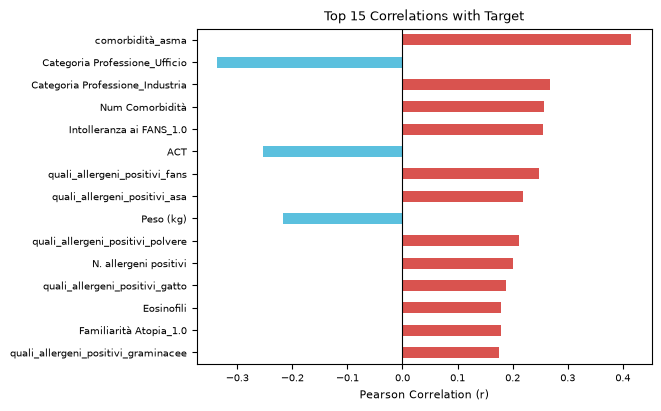

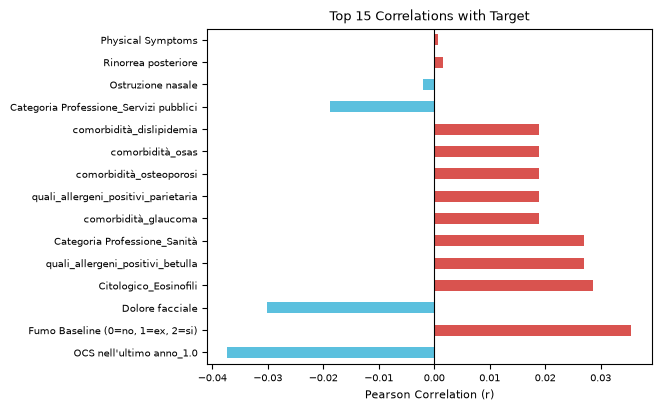

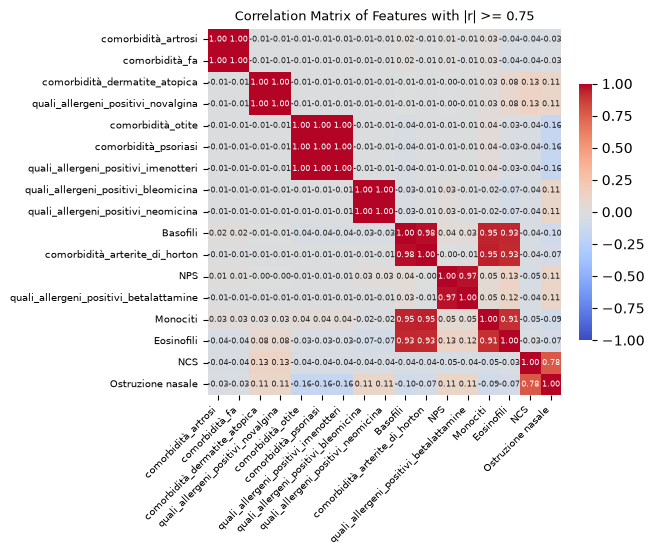

Test 6 successfully saved.


In [25]:

import gspread
import json
from pathlib import Path

# ============================================================
# GOOGLE SHEETS CONNECTION
# ============================================================

CREDENTIALS_PATH = "credentials.json"
SPREADSHEET_ID = "1pzs31DgAVyZuE2g-QWQKbgaH87kO_IBSnrM9HXrxrVQ"
WORKSHEET_NAME = "Foglio1"

gc = gspread.service_account(filename=CREDENTIALS_PATH)
sheet = gc.open_by_key(SPREADSHEET_ID).worksheet(WORKSHEET_NAME)

# ============================================================
# SERIALIZATION
# ============================================================

def to_json(obj):
    return json.dumps(obj, ensure_ascii=False, default=str)


# ============================================================
# EXCLUDED FEATURES
# ============================================================

active_features = {
    name: list(columns)
    for name, transformer, columns in ct.transformers
    if transformer != "drop"
}

excluded_features = {
    name: ", ".join(
        col for col in original_cols
        if col not in active_features.get(name, [])
    )
    for name, original_cols in all_features.items()
}

# ============================================================
# TRAIN SIZE
# ============================================================

train_size = len(X_train) / (len(X_train) + len(X_test))

# ============================================================
# PREPROCESSING
# ============================================================

transformers = {
    name: transformer
    for name, transformer, columns in ct.transformers
}


def get_step(group, step_type, attribute):
    transformer = transformers.get(group)
    if isinstance(transformer, Pipeline):
        transformer = next(
            (step for _, step in transformer.steps if isinstance(step, step_type)),
            None,
        )
    if not isinstance(transformer, step_type):
        return "None"
    return type(transformer).__name__ if attribute == "type" else getattr(transformer, attribute)


cont_imputer = get_step("num_cont", SimpleImputer, "strategy")
cont_scaler = get_step("num_cont", StandardScaler, "type")
discr_imputer = get_step("num_discr", SimpleImputer, "strategy")
discr_scaler = get_step("num_discr", StandardScaler, "type")
cat_imputer = get_step("cat", SimpleImputer, "strategy")
cat_encoder = get_step("cat", OneHotEncoder, "type")
multi_cat_imputer = "None"
multicat_encoder = (
    "MultiLabelBinarizer"
    if isinstance(transformers.get("multi_cat"), MultiColumnBinarizer)
    else "None"
)
ord_imputer = get_step("ord", SimpleImputer, "strategy")
ord_scaler = get_step("ord", StandardScaler, "type")

# ============================================================
# MODEL PARAMETERS AND RESULTS
# ============================================================

def get_model_info(model_name):
    model = best_models[model_name]
    y_pred = model.predict(X_test)
    test_results = {
        "f1_macro": round(f1_score(y_test, y_pred, average="macro"), 4),
        "accuracy": round(accuracy_score(y_test, y_pred), 4),
        "precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
    }
    return to_json(best_params[model_name]), to_json(test_results)


svc_params, svc_results = get_model_info("LinearSVC")
rf_params, rf_results = get_model_info("RandomForestClassifier")
lr_params, lr_results = get_model_info("LogisticRegression")

# ============================================================
# TEST ID
# ============================================================

existing_ids = [
    int(value)
    for value in sheet.col_values(1)[1:]
    if value.strip().isdigit()
]

test_id = max(existing_ids, default=0) + 1

project_root = Path.cwd()
if project_root.name == "src" and project_root.parent.name == "Notebooks":
    project_root = project_root.parent.parent
output_dir = project_root / "output" / f"Test{test_id}"
output_dir.mkdir(parents=True, exist_ok=False)
analyze_feature_correlations(
    ct, X_train, y_train, top_n_target=15, corr_threshold=0.75,
    output_dir=output_dir,
)

# ============================================================
# APPEND ROW
# ============================================================

row = [
    test_id,
    excluded_features["num_cont"],
    excluded_features["num_discr"],
    excluded_features["cat"],
    excluded_features["multi_cat"],
    excluded_features["ord"],
    train_size,
    cont_imputer,
    cont_scaler,
    discr_imputer,
    discr_scaler,
    cat_imputer,
    cat_encoder,
    multi_cat_imputer,
    multicat_encoder,
    ord_imputer,
    ord_scaler,
    svc_params,
    svc_results,
    rf_params,
    rf_results,
    lr_params,
    lr_results,
    cv_folds["LinearSVC"],
]

if sheet.cell(1, 24).value != "CV folds":
    sheet.update_cell(1, 24, "CV folds")

sheet.append_row(
    row,
    value_input_option="RAW",
    table_range="A1:X1"
)

print(f"Test {test_id} successfully saved.")


In [20]:
import gspread

# Connection parameters

CREDENTIALS_PATH = "credentials.json"
SPREADSHEET_ID = "1pzs31DgAVyZuE2g-QWQKbgaH87kO_IBSnrM9HXrxrVQ"
WORKSHEET_NAME = "Foglio1"


try:
    # Authentication
    gc = gspread.service_account(filename=CREDENTIALS_PATH)
    print("[OK] Authentication successful")

    # Spreadsheet access
    spreadsheet = gc.open_by_key(SPREADSHEET_ID)
    print(f"[OK] Spreadsheet found: {spreadsheet.title}")

    # Worksheet access
    sheet = spreadsheet.worksheet(WORKSHEET_NAME)
    print(f"[OK] Worksheet found: {sheet.title}")

    # Read headers
    headers = sheet.row_values(1)

    print("\nColumn headers:")
    for i, header in enumerate(headers, start=1):
        print(f"  {i}. {header}")

    print("\n[SUCCESS] Connection established successfully.")

except Exception as e:
    print(f"\n[ERROR] {type(e).__name__}: {e}")

[OK] Authentication successful
[OK] Spreadsheet found: Test Binary
[OK] Worksheet found: Foglio1

Column headers:
  1. Test ID
  2. excluded continuous 
  3. exclued discrete
  4. excluded categorical
  5. excluded multicat
  6. excluded ordinal
  7. train size
  8. cont inputer
  9. cont scaler
  10. discr imputer 
  11. discr scaler
  12. cat imputer 
  13. cat encoder
  14. multi cat imputer 
  15. multicat encoder
  16. ord imputer
  17. ord scaler
  18. SVC params
  19. SVC results
  20. RF params
  21. RF results
  22. LR params
  23. LR results
  24. CV folds
  25. NOTE per prossimo test

[SUCCESS] Connection established successfully.
